In [1]:
import statsmodels.api as sm
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

In [2]:
tips = sns.load_dataset("tips")
tips

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


In [3]:
tips[['tip','total_bill','size']].corr()

,tip,total_bill,size
tip,1.000000,0.675734,0.489299
total_bill,0.675734,1.000000,0.598315
size,0.489299,0.598315,1.000000


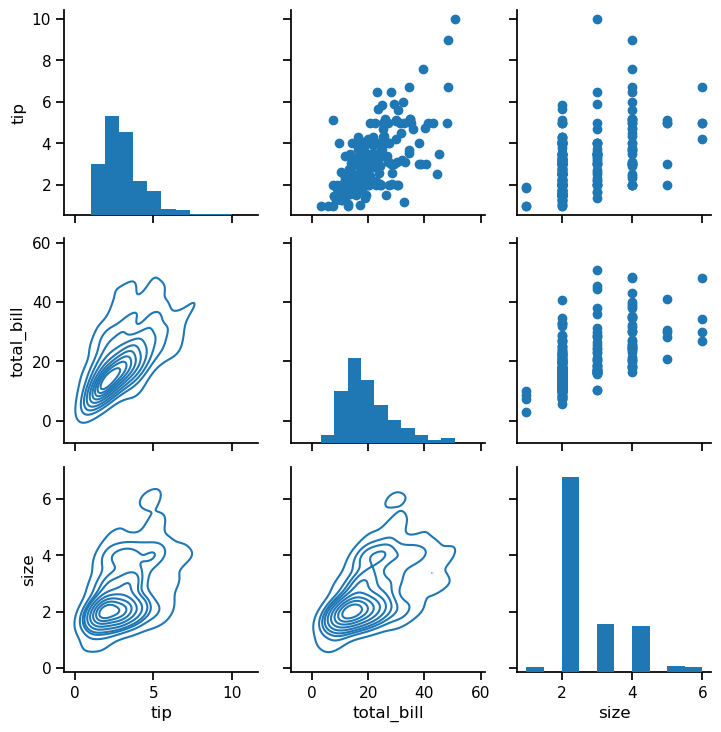

In [4]:
sns.set_context('notebook',font_scale=1)
g = sns.PairGrid(tips[['tip','total_bill','size']])
g.map_diag(plt.hist)
g.map_upper(plt.scatter)
g.map_lower(sns.kdeplot)

In [5]:
# apply multiple linear regression
Y = tips['tip']
X = sm.add_constant(tips[['total_bill', 'size']])

display(Y,X)

0      1.01
1      1.66
2      3.50
3      3.31
4      3.61
       ... 
239    5.92
240    2.00
241    2.00
242    1.75
243    3.00
Name: tip, Length: 244, dtype: float64

,const,total_bill,size
0,1.0,16.99,2
1,1.0,10.34,3
2,1.0,21.01,3
3,1.0,23.68,2
4,1.0,24.59,4
...,...,...,...
239,1.0,29.03,3
240,1.0,27.18,2
241,1.0,22.67,2
242,1.0,17.82,2


In [6]:
# execute
sm_lm = sm.OLS(Y,X)
result = sm_lm.fit()

In [7]:
# show the summary
print(result.summary())

                            OLS Regression Results                            
Dep. Variable:                    tip   R-squared:                       0.468
Model:                            OLS   Adj. R-squared:                  0.463
Method:                 Least Squares   F-statistic:                     105.9
Date:                Wed, 29 May 2024   Prob (F-statistic):           9.67e-34
Time:                        11:40:50   Log-Likelihood:                -347.99
No. Observations:                 244   AIC:                             702.0
Df Residuals:                     241   BIC:                             712.5
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.6689      0.194      3.455      0.0

In [8]:
tips[['tip','total_bill','size']].describe().T

,count,mean,std,min,25%,50%,75%,max
tip,244.0,2.998279,1.383638,1.00,2.0000,2.900,3.5625,10.00
total_bill,244.0,19.785943,8.902412,3.07,13.3475,17.795,24.1275,50.81
size,244.0,2.569672,0.951100,1.00,2.0000,2.000,3.0000,6.00


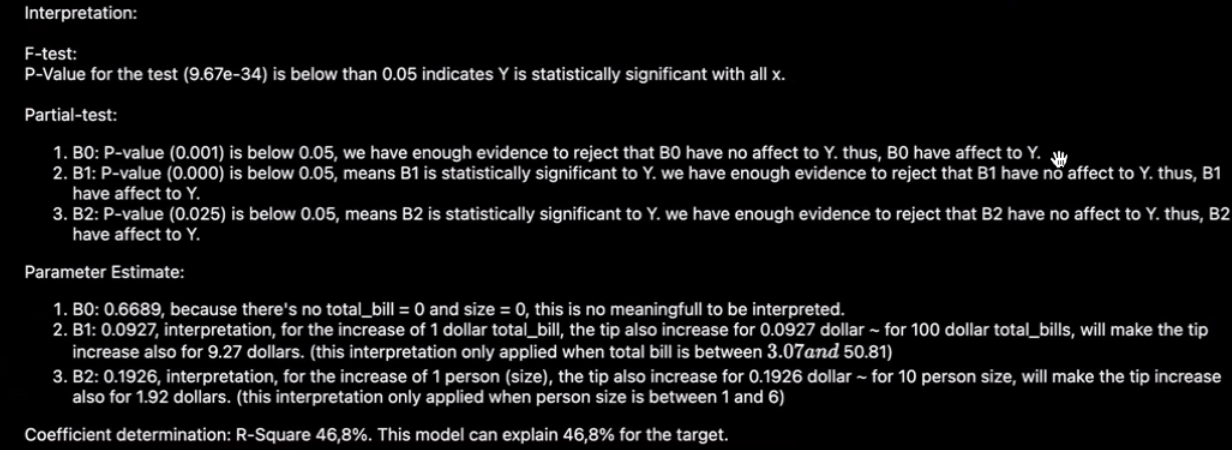

In [9]:
display(result.fittedvalues, result.resid)

0      2.629340
1      2.205394
2      3.194645
3      3.249592
4      3.719157
         ...   
239    3.938206
240    3.574089
241    3.155952
242    2.706292
243    2.795297
Length: 244, dtype: float64

0     -1.619340
1     -0.545394
2      0.305355
3      0.060408
4     -0.109157
         ...   
239    1.981794
240   -1.574089
241   -1.155952
242   -0.956292
243    0.204703
Length: 244, dtype: float64

In [10]:
tips['y_pred'] = pd.DataFrame(result.fittedvalues, columns=['prediction'])
tips['residual'] = pd.DataFrame(result.resid, columns=['resid'])
tips

,total_bill,tip,sex,smoker,day,time,size,y_pred,residual
0,16.99,1.01,Female,No,Sun,Dinner,2,2.629340,-1.619340
1,10.34,1.66,Male,No,Sun,Dinner,3,2.205394,-0.545394
2,21.01,3.50,Male,No,Sun,Dinner,3,3.194645,0.305355
3,23.68,3.31,Male,No,Sun,Dinner,2,3.249592,0.060408
4,24.59,3.61,Female,No,Sun,Dinner,4,3.719157,-0.109157
...,...,...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3,3.938206,1.981794
240,27.18,2.00,Female,Yes,Sat,Dinner,2,3.574089,-1.574089
241,22.67,2.00,Male,Yes,Sat,Dinner,2,3.155952,-1.155952
242,17.82,1.75,Male,No,Sat,Dinner,2,2.706292,-0.956292


Text(0.5, 0, 'Residual')

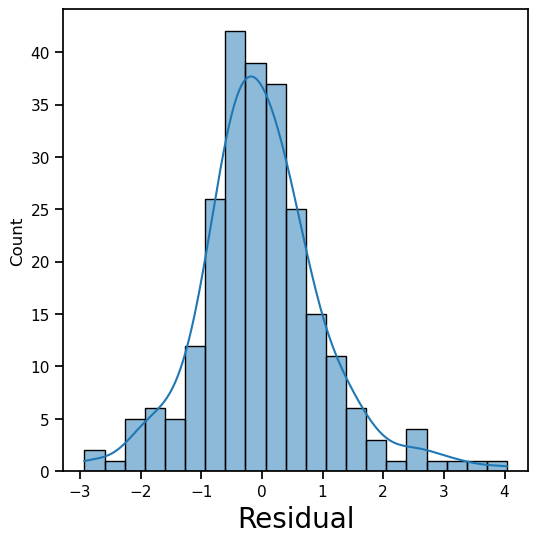

In [11]:
# normality assumption 
plt.figure(figsize=(6,6))
sns.set_context('notebook',font_scale=1)
sns.histplot(tips['residual'], kde=True)
plt.xlabel('Residual',fontsize=20)


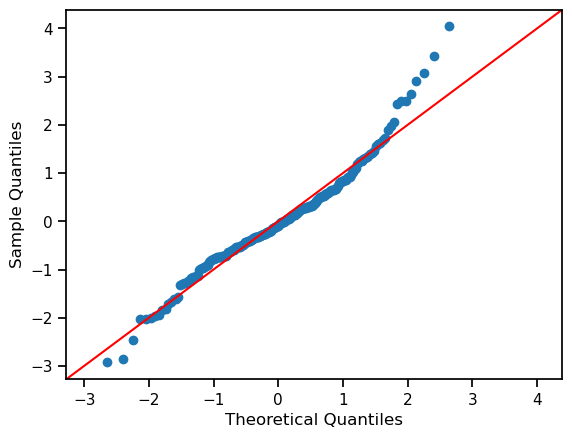

In [12]:
# QQ plot
sm.qqplot(tips['residual'],line='45')
plt.show()

Text(0, 0.5, 'Residual')

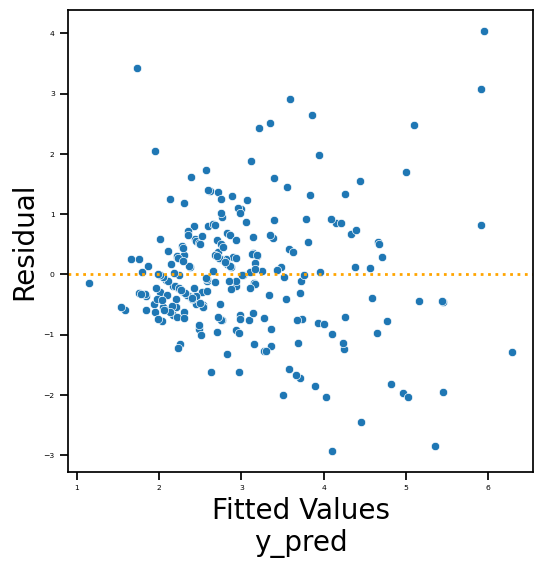

In [13]:
# Gauss-markov -> Heterocedastic
plt.figure(figsize=(6,6))
sns.set_context('notebook',font_scale=0.5)
ax = sns.scatterplot(data=tips,x='y_pred',y='residual')
ax.axhline(y=0, linewidth = 2, color='orange', ls=':')
plt.xlabel('Fitted Values\ny_pred',fontsize=20)
plt.ylabel('Residual',fontsize=20)

In [14]:
# multicollinearity check
from statsmodels.stats.outliers_influence import variance_inflation_factor
def calc_vif(X):
    vif = pd.DataFrame()
    vif['variables'] = X.columns
    vif['VIF'] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
    return(vif)

In [15]:
calc_vif(tips[['total_bill', 'size']])

,variables,VIF
0,total_bill,8.684373
1,size,8.684373


In [16]:
a = tips['sex'].value_counts()
b = tips['smoker'].value_counts()
c = tips['day'].value_counts()
d = tips['time'].value_counts()
display(a,b,c,d)

sex
Male      157
Female     87
Name: count, dtype: int64

smoker
No     151
Yes     93
Name: count, dtype: int64

day
Sat     87
Sun     76
Thur    62
Fri     19
Name: count, dtype: int64

time
Dinner    176
Lunch      68
Name: count, dtype: int64

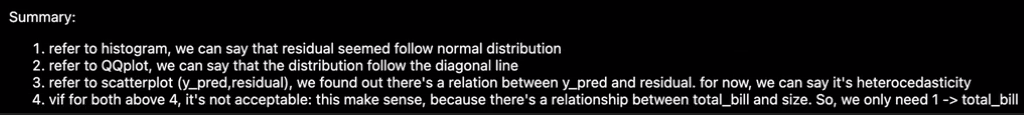

In [17]:
tips_dummy = pd.get_dummies(tips, columns=['sex', 'smoker', 'day', 'time'])*1
tips_dummy

,total_bill,tip,size,y_pred,residual,sex_Male,sex_Female,smoker_Yes,smoker_No,day_Thur,day_Fri,day_Sat,day_Sun,time_Lunch,time_Dinner
0,16.99,1.01,2,2.629340,-1.619340,0,1,0,1,0,0,0,1,0,1
1,10.34,1.66,3,2.205394,-0.545394,1,0,0,1,0,0,0,1,0,1
2,21.01,3.50,3,3.194645,0.305355,1,0,0,1,0,0,0,1,0,1
3,23.68,3.31,2,3.249592,0.060408,1,0,0,1,0,0,0,1,0,1
4,24.59,3.61,4,3.719157,-0.109157,0,1,0,1,0,0,0,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
239,29.03,5.92,3,3.938206,1.981794,1,0,0,1,0,0,1,0,0,1
240,27.18,2.00,2,3.574089,-1.574089,0,1,1,0,0,0,1,0,0,1
241,22.67,2.00,2,3.155952,-1.155952,1,0,1,0,0,0,1,0,0,1
242,17.82,1.75,2,2.706292,-0.956292,1,0,0,1,0,0,1,0,0,1
